In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


In [2]:
# Step 2: Upload dataset in Colab
from google.colab import files
uploaded = files.upload()


Saving heart_cleaned_no_outliers_encoded_Featured_Standardized.csv to heart_cleaned_no_outliers_encoded_Featured_Standardized.csv


In [3]:
# Load dataset
df = pd.read_csv("heart_cleaned_no_outliers_encoded_Featured_Standardized.csv")

# Show dataset info and preview
print(df.info())
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 889 entries, 0 to 888
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   thalach              889 non-null    float64
 1   oldpeak              889 non-null    float64
 2   exang_encoded        889 non-null    float64
 3   slope_encoded        889 non-null    float64
 4   ca_encoded           889 non-null    float64
 5   thal_encoded         889 non-null    float64
 6   sex_Female           889 non-null    float64
 7   sex_Male             889 non-null    float64
 8   cp_Non-anginal pain  889 non-null    float64
 9   cp_Typical angina    889 non-null    float64
 10  target               889 non-null    int64  
dtypes: float64(10), int64(1)
memory usage: 76.5 KB
None


,thalach,oldpeak,exang_encoded,slope_encoded,ca_encoded,thal_encoded,sex_Female,sex_Male,cp_Non-anginal pain,cp_Typical angina,target
0,0.781616,0.020140,-0.699366,0.952760,2.034629,0.797548,-0.648173,0.648173,-0.615057,1.071141,0
1,0.200595,2.020120,1.429867,-2.336574,-0.722666,0.797548,-0.648173,0.648173,-0.615057,1.071141,0
2,-1.140223,1.543934,1.429867,-2.336574,-0.722666,0.797548,-0.648173,0.648173,-0.615057,1.071141,0
3,0.468758,-0.932231,-0.699366,0.952760,0.655982,0.797548,-0.648173,0.648173,-0.615057,1.071141,0
4,-1.274304,0.020140,-0.699366,-0.691907,-0.722666,-0.828645,1.542799,-1.542799,-0.615057,1.071141,1


In [4]:
# Step 3: Split into features and target
X = df.drop(columns=['target'])
y = df['target']


In [5]:
# Step 4: Apply PCA keeping all components
pca = PCA()
X_pca = pca.fit_transform(X)


In [6]:
# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance per component:\n", explained_variance)
print("\nCumulative explained variance:\n", cumulative_variance)


Explained variance per component:
 [0.33139845 0.18409503 0.12689397 0.09005861 0.07507189 0.06442623
 0.05424212 0.03947766 0.03433603 0.        ]

Cumulative explained variance:
 [0.33139845 0.51549348 0.64238746 0.73244607 0.80751795 0.87194419
 0.92618631 0.96566397 1.         1.        ]


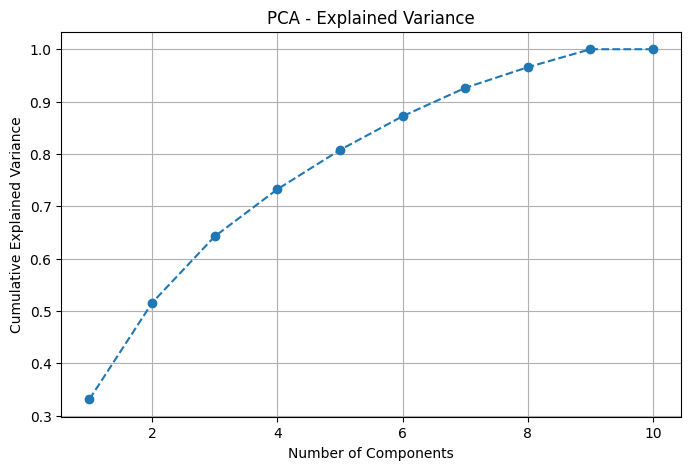

In [7]:
# Step 5: Plot cumulative explained variance
plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_variance)+1), cumulative_variance, marker='o', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid(True)
plt.show()


In [8]:
# Step 6: apply PCA with 7 components
pca_final = PCA(n_components=7)
X_pca_final = pca_final.fit_transform(X)

# create  dataFrame with PCA components
df_pca_final = pd.DataFrame(X_pca_final, columns=[f'PC{i+1}' for i in range(7)])

# target column
df_pca_final['target'] = y

df_pca_final.head()


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,target
0,0.954224,-0.944733,-1.630119,1.815879,0.569696,0.749509,0.433992,0
1,2.870438,0.431430,1.183963,-1.520670,1.440896,-0.552035,0.720898,0
2,3.128135,0.723243,1.253407,-1.562350,0.459671,-0.310129,-0.190071,0
3,0.409888,-1.197789,-1.666070,0.453634,-0.170592,0.937658,0.134562,0
4,-0.499148,2.515816,-0.365369,-0.992421,0.126795,0.542113,-1.236155,1


In [9]:
# Step 7: Save PCA dataset to CSV
df_pca_final.to_csv("heart_dataset_pca.csv", index=False)

from google.colab import files
files.download("heart_dataset_pca.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>